In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

# Các thư viện tiền xử lý và xây dựng mô hình
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR

# Các chỉ số đánh giá
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

print("Import thư viện thành công!")

Import thư viện thành công!


In [3]:
file_path = Path("../data/processed/online_retail_sales.csv")

df = pd.read_csv(file_path, low_memory=False)

df["Invoice"] = df["Invoice"].astype("string")
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])

print("Kích thước dữ liệu:", df.shape)
print("Khoảng thời gian:", df["InvoiceDate"].min(), "đến", df["InvoiceDate"].max())

display(df.head())

Kích thước dữ liệu: (1029609, 13)
Khoảng thời gian: 2009-12-01 07:45:00 đến 2011-12-09 12:50:00


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,SourceSheet,IsCancelled,IsSpecialAdjustment,IsNegativePrice,Revenue
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom,Year 2009-2010,False,False,False,83.4
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,Year 2009-2010,False,False,False,81.0
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,Year 2009-2010,False,False,False,81.0
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom,Year 2009-2010,False,False,False,100.8
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom,Year 2009-2010,False,False,False,30.0


In [4]:
daily_df = (
    df.set_index("InvoiceDate")["Revenue"]
    .resample("D")
    .sum()
    .reset_index()
)

daily_df.rename(columns={"InvoiceDate": "Date"}, inplace=True)

daily_df = daily_df.sort_values("Date").reset_index(drop=True)

display(daily_df.head(10))

print("Kích thước dữ liệu:", daily_df.shape)
print("Ngày bắt đầu:", daily_df["Date"].min())
print("Ngày kết thúc:", daily_df["Date"].max())
print("Số ngày:", daily_df["Date"].nunique())
print("Số ngày không phát sinh doanh thu:", (daily_df["Revenue"] == 0).sum())

,Date,Revenue
0,2009-12-01,54351.23
1,2009-12-02,63172.58
2,2009-12-03,73972.45
3,2009-12-04,40582.32
4,2009-12-05,9803.05
5,2009-12-06,24423.02
6,2009-12-07,44916.21
7,2009-12-08,49476.23
8,2009-12-09,40265.66
9,2009-12-10,44233.96


Kích thước dữ liệu: (739, 2)
Ngày bắt đầu: 2009-12-01 00:00:00
Ngày kết thúc: 2011-12-09 00:00:00
Số ngày: 739
Số ngày không phát sinh doanh thu: 135


In [5]:
daily_df["Year"] = daily_df["Date"].dt.year
daily_df["Month"] = daily_df["Date"].dt.month
daily_df["Day"] = daily_df["Date"].dt.day
daily_df["DayOfWeek"] = daily_df["Date"].dt.dayofweek
daily_df["IsWeekend"] = (daily_df["DayOfWeek"] >= 5).astype(int)

display(daily_df.head(10))

,Date,Revenue,Year,Month,Day,DayOfWeek,IsWeekend
0,2009-12-01,54351.23,2009,12,1,1,0
1,2009-12-02,63172.58,2009,12,2,2,0
2,2009-12-03,73972.45,2009,12,3,3,0
3,2009-12-04,40582.32,2009,12,4,4,0
4,2009-12-05,9803.05,2009,12,5,5,1
5,2009-12-06,24423.02,2009,12,6,6,1
6,2009-12-07,44916.21,2009,12,7,0,0
7,2009-12-08,49476.23,2009,12,8,1,0
8,2009-12-09,40265.66,2009,12,9,2,0
9,2009-12-10,44233.96,2009,12,10,3,0


In [6]:
daily_df["Lag_1"] = daily_df["Revenue"].shift(1)
daily_df["Lag_7"] = daily_df["Revenue"].shift(7)

daily_df["Rolling_Mean_7"] = (
    daily_df["Revenue"].shift(1).rolling(window=7).mean()
)

daily_df["Rolling_Mean_30"] = (
    daily_df["Revenue"].shift(1).rolling(window=30).mean()
)

display(daily_df.head(35))

,Date,Revenue,Year,Month,Day,DayOfWeek,IsWeekend,Lag_1,Lag_7,Rolling_Mean_7,Rolling_Mean_30
0,2009-12-01,54351.23,2009,12,1,1,0,NaN,NaN,NaN,NaN
1,2009-12-02,63172.58,2009,12,2,2,0,54351.23,NaN,NaN,NaN
2,2009-12-03,73972.45,2009,12,3,3,0,63172.58,NaN,NaN,NaN
3,2009-12-04,40582.32,2009,12,4,4,0,73972.45,NaN,NaN,NaN
4,2009-12-05,9803.05,2009,12,5,5,1,40582.32,NaN,NaN,NaN
5,2009-12-06,24423.02,2009,12,6,6,1,9803.05,NaN,NaN,NaN
6,2009-12-07,44916.21,2009,12,7,0,0,24423.02,NaN,NaN,NaN
7,2009-12-08,49476.23,2009,12,8,1,0,44916.21,54351.23,44460.122857,NaN
8,2009-12-09,40265.66,2009,12,9,2,0,49476.23,63172.58,43763.694286,NaN
9,2009-12-10,44233.96,2009,12,10,3,0,40265.66,73972.45,40491.277143,NaN


In [7]:
# Loại bỏ các dòng thiếu dữ liệu do tạo Lag và Rolling
daily_df = daily_df.dropna().reset_index(drop=True)

print("Kích thước sau khi xử lý:", daily_df.shape)
print("Số giá trị thiếu:", daily_df.isnull().sum().sum())

display(daily_df.head())

Kích thước sau khi xử lý: (709, 11)
Số giá trị thiếu: 0


,Date,Revenue,Year,Month,Day,DayOfWeek,IsWeekend,Lag_1,Lag_7,Rolling_Mean_7,Rolling_Mean_30
0,2009-12-31,0.0,2009,12,31,3,0,0.0,0.0,0.0,27416.131667
1,2010-01-01,0.0,2010,1,1,4,0,0.0,0.0,0.0,25604.424000
2,2010-01-02,0.0,2010,1,2,5,1,0.0,0.0,0.0,23498.671333
3,2010-01-03,0.0,2010,1,3,6,1,0.0,0.0,0.0,21032.923000
4,2010-01-04,13445.8,2010,1,4,0,0,0.0,0.0,0.0,19680.179000


In [8]:
# Xác định vị trí chia dữ liệu
split_index = int(len(daily_df) * 0.8)

# Chia Train/Test theo thứ tự thời gian
train_df = daily_df.iloc[:split_index].copy()
test_df = daily_df.iloc[split_index:].copy()

print("Train:", train_df.shape)
print("Test:", test_df.shape)

print("\nKhoảng thời gian Train:")
print(train_df["Date"].min(), "đến", train_df["Date"].max())

print("\nKhoảng thời gian Test:")
print(test_df["Date"].min(), "đến", test_df["Date"].max())

Train: (567, 11)
Test: (142, 11)

Khoảng thời gian Train:
2009-12-31 00:00:00 đến 2011-07-20 00:00:00

Khoảng thời gian Test:
2011-07-21 00:00:00 đến 2011-12-09 00:00:00


In [9]:
# Các đặc trưng đầu vào
feature_cols = [
    "Year",
    "Month",
    "Day",
    "DayOfWeek",
    "IsWeekend",
    "Lag_1",
    "Lag_7",
    "Rolling_Mean_7",
    "Rolling_Mean_30"
]

# Biến mục tiêu
target_col = "Revenue"

# Tách X và y
X_train = train_df[feature_cols]
y_train = train_df[target_col]

X_test = test_df[feature_cols]
y_test = test_df[target_col]

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

X_train: (567, 9)
y_train: (567,)
X_test: (142, 9)
y_test: (142,)


In [10]:
models = {
    "Linear Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LinearRegression())
    ]),

    "Decision Tree": Pipeline([
        ("model", DecisionTreeRegressor(random_state=42))
    ]),

    "Random Forest": Pipeline([
        ("model", RandomForestRegressor(
            n_estimators=100,
            random_state=42
        ))
    ]),

    "SVR": Pipeline([
        ("scaler", StandardScaler()),
        ("model", SVR(kernel="rbf"))
    ])
}

print("Đã khởi tạo 4 mô hình thành công!")

Đã khởi tạo 4 mô hình thành công!


In [11]:
for name, model in models.items():
    model.fit(X_train, y_train)
    print(f"{name}: Huấn luyện thành công!")

Linear Regression: Huấn luyện thành công!
Decision Tree: Huấn luyện thành công!
Random Forest: Huấn luyện thành công!
SVR: Huấn luyện thành công!


In [12]:
predictions = {}

for name, model in models.items():
    y_pred = model.predict(X_test)
    predictions[name] = y_pred

    print(f"{name}: Dự đoán hoàn thành!")

Linear Regression: Dự đoán hoàn thành!
Decision Tree: Dự đoán hoàn thành!
Random Forest: Dự đoán hoàn thành!
SVR: Dự đoán hoàn thành!


In [13]:
results = []

for name, y_pred in predictions.items():
    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)

    results.append({
        "Model": name,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2": r2
    })

results_df = pd.DataFrame(results)

display(results_df.round(4))

,Model,MAE,MSE,RMSE,R2
0,Linear Regression,13793.9903,4.242957e+08,20598.4400,0.4604
1,Decision Tree,15835.9781,5.692119e+08,23858.1632,0.2761
2,Random Forest,11420.2470,3.388354e+08,18407.4812,0.5691
3,SVR,22745.6157,9.569650e+08,30934.8503,-0.2170


In [14]:
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit

param_grid = {
    "model__n_estimators": [100, 200, 300],
    "model__max_depth": [None, 5, 10, 15],
    "model__min_samples_split": [2, 5, 10],
    "model__min_samples_leaf": [1, 2, 4]
}

rf_pipeline = Pipeline([
    ("model", RandomForestRegressor(random_state=42))
])

tscv = TimeSeriesSplit(n_splits=5)

grid_search = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=param_grid,
    cv=tscv,
    scoring="neg_mean_absolute_error",
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, y_train)

print("Tham số tốt nhất:", grid_search.best_params_)
print("MAE tốt nhất trên Cross Validation:", -grid_search.best_score_)

Fitting 5 folds for each of 108 candidates, totalling 540 fits
Tham số tốt nhất: {'model__max_depth': 5, 'model__min_samples_leaf': 2, 'model__min_samples_split': 10, 'model__n_estimators': 200}
MAE tốt nhất trên Cross Validation: 9437.909308095208


In [15]:
# Lấy mô hình tốt nhất từ Grid Search
best_rf = grid_search.best_estimator_

# Dự đoán trên tập Test
y_pred_rf = best_rf.predict(X_test)

# Tính các chỉ số đánh giá
mae = mean_absolute_error(y_test, y_pred_rf)
mse = mean_squared_error(y_test, y_pred_rf)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred_rf)

print("KẾT QUẢ RANDOM FOREST SAU TINH CHỈNH")
print("MAE:", round(mae, 4))
print("MSE:", round(mse, 4))
print("RMSE:", round(rmse, 4))
print("R2:", round(r2, 4))

KẾT QUẢ RANDOM FOREST SAU TINH CHỈNH
MAE: 11167.3383
MSE: 336376506.173
RMSE: 18340.57
R2: 0.5722


In [16]:
comparison_df = pd.DataFrame([
    {
        "Model": "Random Forest Before Tuning",
        "MAE": results_df.loc[
            results_df["Model"] == "Random Forest", "MAE"
        ].iloc[0],
        "RMSE": results_df.loc[
            results_df["Model"] == "Random Forest", "RMSE"
        ].iloc[0],
        "R2": results_df.loc[
            results_df["Model"] == "Random Forest", "R2"
        ].iloc[0]
    },
    {
        "Model": "Random Forest After Tuning",
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    }
])

display(comparison_df.round(4))

,Model,MAE,RMSE,R2
0,Random Forest Before Tuning,11420.2470,18407.4812,0.5691
1,Random Forest After Tuning,11167.3383,18340.5700,0.5722


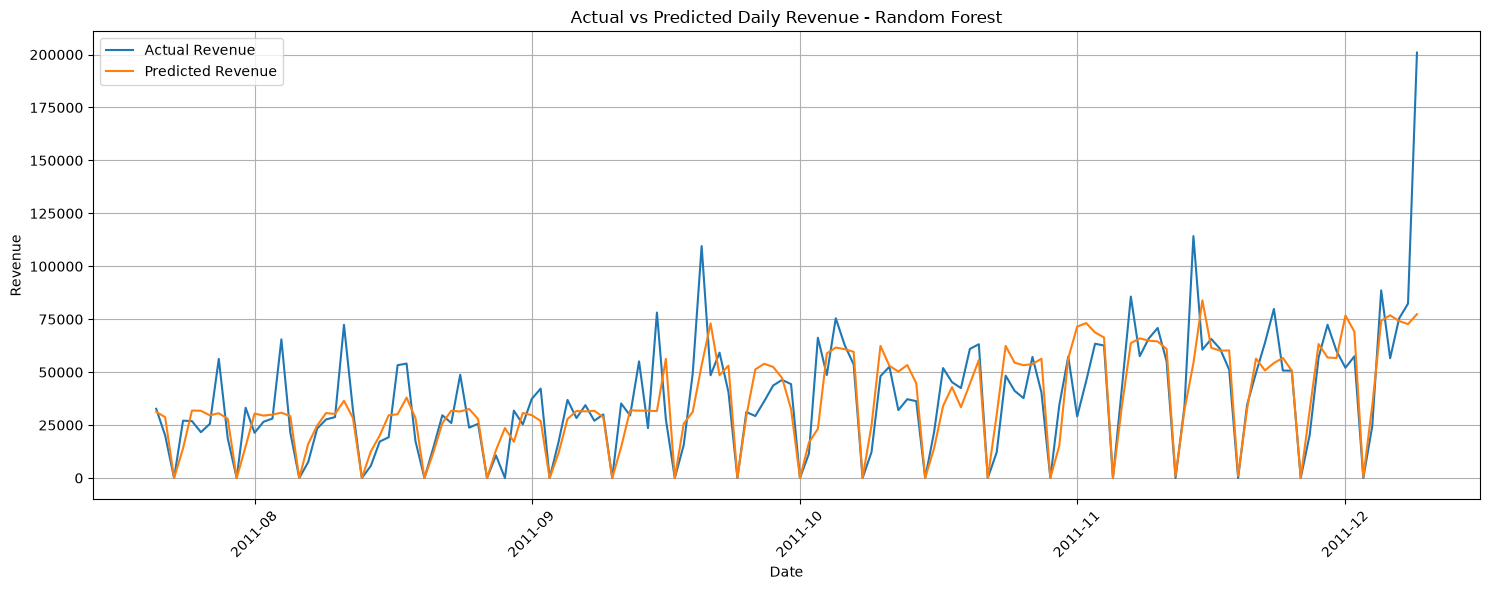

In [17]:
plt.figure(figsize=(15, 6))

plt.plot(
    test_df["Date"],
    y_test.values,
    label="Actual Revenue"
)

plt.plot(
    test_df["Date"],
    y_pred_rf,
    label="Predicted Revenue"
)

plt.title("Actual vs Predicted Daily Revenue - Random Forest")
plt.xlabel("Date")
plt.ylabel("Revenue")
plt.legend()
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

,Importance
Rolling_Mean_7,0.319440
Lag_7,0.178244
IsWeekend,0.159302
DayOfWeek,0.141096
Lag_1,0.119126
Day,0.038799
Rolling_Mean_30,0.027801
Month,0.013909
Year,0.002282


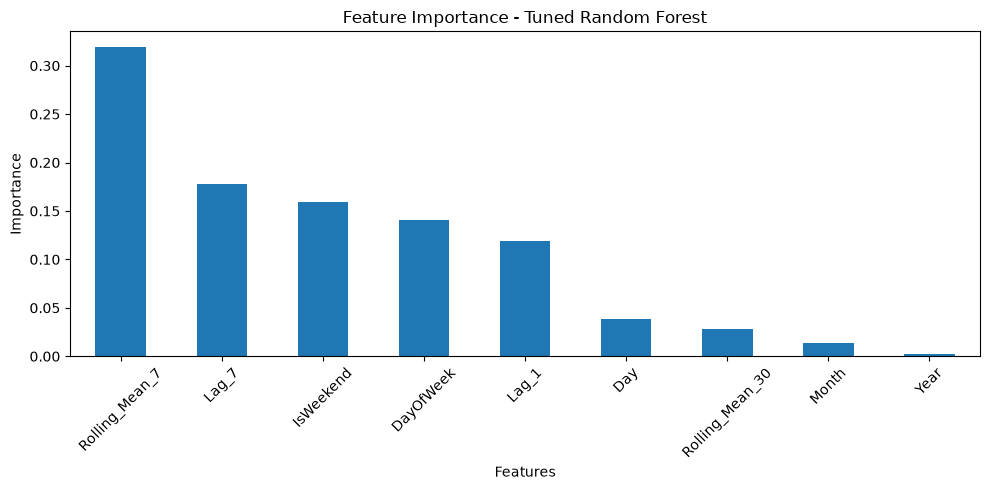

In [18]:
importances = pd.Series(
    best_rf.named_steps["model"].feature_importances_,
    index=feature_cols
).sort_values(ascending=False)

display(importances.to_frame("Importance"))

plt.figure(figsize=(10, 5))
importances.plot(kind="bar")

plt.title("Feature Importance - Tuned Random Forest")
plt.xlabel("Features")
plt.ylabel("Importance")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [23]:

# Lấy dữ liệu doanh thu lịch sử
history = daily_df["Revenue"].tolist()

# Xác định ngày tiếp theo
next_date = daily_df["Date"].max() + pd.Timedelta(days=1)

# Tạo đặc trưng cho ngày cần dự đoán
next_features = pd.DataFrame([{
    "Year": next_date.year,
    "Month": next_date.month,
    "Day": next_date.day,
    "DayOfWeek": next_date.dayofweek,
    "IsWeekend": int(next_date.dayofweek >= 5),
    "Lag_1": history[-1],
    "Lag_7": history[-7],
    "Rolling_Mean_7": np.mean(history[-7:]),
    "Rolling_Mean_30": np.mean(history[-30:])
}])

# Dự đoán bằng Random Forest đã tinh chỉnh
next_prediction = best_rf.predict(next_features)[0]

print("Ngày dự đoán:", next_date.date())
print("Doanh thu dự đoán:", round(next_prediction, 2))


Ngày dự đoán: 2011-12-10
Doanh thu dự đoán: 12234.42


In [24]:

# Sao chép lịch sử doanh thu
future_history = daily_df["Revenue"].tolist()

# Ngày cuối cùng trong dữ liệu
last_date = daily_df["Date"].max()

future_predictions = []

# Dự đoán 7 ngày tiếp theo
for i in range(1, 8):

    forecast_date = last_date + pd.Timedelta(days=i)

    # Tạo đặc trưng
    future_features = pd.DataFrame([{
        "Year": forecast_date.year,
        "Month": forecast_date.month,
        "Day": forecast_date.day,
        "DayOfWeek": forecast_date.dayofweek,
        "IsWeekend": int(forecast_date.dayofweek >= 5),
        "Lag_1": future_history[-1],
        "Lag_7": future_history[-7],
        "Rolling_Mean_7": np.mean(future_history[-7:]),
        "Rolling_Mean_30": np.mean(future_history[-30:])
    }])

    # Dự đoán
    predicted_revenue = best_rf.predict(future_features)[0]

    # Lưu kết quả
    future_predictions.append({
        "Date": forecast_date,
        "Predicted_Revenue": predicted_revenue
    })

    # Bổ sung kết quả dự đoán vào lịch sử
    future_history.append(predicted_revenue)

# Hiển thị kết quả
future_df = pd.DataFrame(future_predictions)

display(
    future_df.style.format({
        "Predicted_Revenue": "{:,.2f}"
    })
)

,Date,Predicted_Revenue
0,2011-12-10 00:00:00,"12,234.42"
1,2011-12-11 00:00:00,"34,369.67"
2,2011-12-12 00:00:00,"66,629.46"
3,2011-12-13 00:00:00,"73,081.61"
4,2011-12-14 00:00:00,"71,442.30"
5,2011-12-15 00:00:00,"71,155.51"
6,2011-12-16 00:00:00,"69,187.62"


Kết quả phân tích EDA được sử dụng làm cơ sở lựa chọn và xây dựng các đặc trưng đầu vào cho mô hình dự đoán doanh thu. Cụ thể, nhóm nhận thấy doanh thu có sự biến động theo thời gian và có tính mùa vụ, do đó đã xây dựng các đặc trưng Year, Month, DayOfWeek và IsWeekend. Ngoài ra, nhóm sử dụng các đặc trưng Lag và Rolling Mean để mô hình khai thác thông tin doanh thu trong quá khứ. Tuy nhiên, các yếu tố về sản phẩm, khách hàng và quốc gia hiện mới được sử dụng trong phân tích khám phá, chưa được đưa trực tiếp vào mô hình dự đoán.